# Instrumental Variables

## Alcance y pregunta

¿Un instrumento válido pero débil produce estimaciones IV inestables?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$x=\pi z+v,\quad y=\beta x+u,\quad Cov(u,v)\neq0$$

β=1; u y v tienen correlación 0.7. El instrumento z es independiente y la fuerza π cambia. Se compara OLS e IV y se informa el estadístico F convencional de la primera etapa. La distribución de IV puede tener colas pesadas.

### Supuestos de identificación

Exclusión y exogeneidad impuestas; una variable endógena y un instrumento; homocedasticidad en el DGP.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

β=1; u y v tienen correlación 0.7. El instrumento z es independiente y la fuerza π cambia. Se compara OLS e IV y se informa el estadístico F convencional de la primera etapa. La distribución de IV puede tener colas pesadas.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=600):
    z=rng.normal(size=n);v=rng.normal(size=n);u=.7*v+np.sqrt(1-.7**2)*rng.normal(size=n)
    x=level*z+v;y=x+u;zc=z-z.mean();xc=x-x.mean()
    iv=np.dot(zc,y-y.mean())/np.dot(zc,xc);ols=ols_fit(y,x[:,None])[0][1]
    first,resid=ols_fit(x,z[:,None]);f=first[1]**2/(np.sum(resid**2)/(n-2)/np.sum(zc**2))
    return {'OLS':ols,'IV':iv,'F primera etapa':f},(z,x)


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0.02, 0.05, 0.1, 0.3, 1.0]
METRICS=['OLS', 'IV', 'F primera etapa']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.1 ; semilla: 20261018


,Métrica,Valor
0,OLS,1.717435
1,IV,1.007605
2,F primera etapa,17.686323


## Sensibilidad y variación entre réplicas

**Eje:** Fuerza de primera etapa π.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.02,OLS,1.70226,1.70759,0.03214,1.64906,1.74718,40,0.00508
1,0.02,IV,1.98629,1.78020,3.28899,-2.10593,5.14652,40,0.52003
2,0.02,F primera etapa,1.35747,0.83100,1.40345,0.01350,4.62257,40,0.22191
3,0.05,OLS,1.70082,1.70723,0.03204,1.64700,1.74688,40,0.00507
4,0.05,IV,1.18811,1.36253,2.64563,-2.70373,7.53333,40,0.41831
5,0.05,F primera etapa,2.49527,1.59787,2.38834,0.02711,7.32526,40,0.37763
6,0.10,OLS,1.69561,1.70360,0.03183,1.64118,1.74332,40,0.00503
7,0.10,IV,0.90971,1.02520,1.35234,-1.12877,1.73170,40,0.21382
8,0.10,F primera etapa,6.83909,5.82172,4.86518,0.19222,15.20884,40,0.76925
9,0.30,OLS,1.64390,1.65063,0.03064,1.58837,1.69470,40,0.00484


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

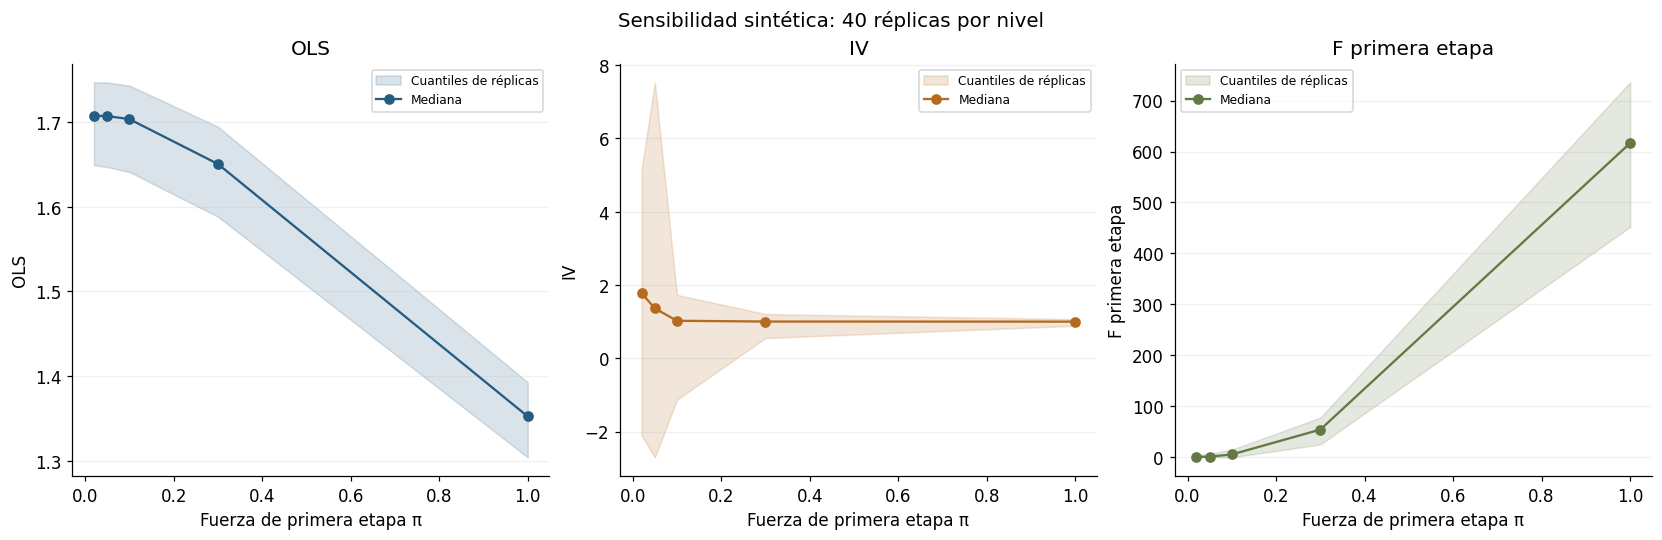

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Fuerza de primera etapa π',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


OLS: mediana 1.70759 en nivel 0.02; 1.35231 en nivel 1.
  Último escenario: cuantiles [1.30388, 1.39271], media 1.34737, error MC de la media 0.004.
IV: mediana 1.7802 en nivel 0.02; 1.00137 en nivel 1.
  Último escenario: cuantiles [0.888168, 1.06884], media 0.994797, error MC de la media 0.00791.
F primera etapa: mediana 0.830995 en nivel 0.02; 616.504 en nivel 1.
  Último escenario: cuantiles [452.12, 735.793], media 608.18, error MC de la media 10.6.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

Una media Monte Carlo de IV es inestable bajo instrumentos débiles. El umbral F=10 no se usa como certificado universal de identificación.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.